# TP2 · Clasificación supervisada — Bank Marketing
## Paso 3 · Ajuste de hiperparámetros con curvas de validación

- Modelos a ajustar: **SVM** (`C`, kernel), **KNN** (`k`, ponderación) y **Random Forest** (`max_depth`, `n_estimators`). Naive Bayes no tiene un hiperparámetro relevante que ajustar y queda como referencia.
- **Datos:** solo `data/train.csv`, con el **set B** elegido en el Paso 2. El test sigue sin usarse.
- **Validación:** los **mismos 5 folds estratificados** del Paso 2, con el preprocesador dentro del `Pipeline` (se ajusta solo con los folds de entrenamiento).
- **Curva de validación** (clase 7): para cada valor del hiperparámetro se grafica el desempeño medio en **train** y en **validación** (± 1 desvío entre folds).
  - Gap grande entre train y validación → **overfitting**.
  - Ambas curvas bajas y juntas → **underfitting**.
- **Criterio de elección:** el valor con **mayor ROC-AUC medio en validación**. Se usa AUC (y no recall) porque el recall depende del umbral, que se fijará recién en el modelo final (Paso 4); el AUC mide la calidad del ranking independientemente del umbral. El recall con umbral por defecto se muestra como complemento.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from joblib import Parallel, delayed

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, roc_auc_score, precision_score

from tp2_comun import (RANDOM_STATE, RESULTADOS, cargar_split, agregar_features, crear_preprocesador,
                       columnas, estilo_graficos, guardar, COLORES_MODELO, C_GRIS)
estilo_graficos()

SET = "B · EDA"
X_train, y_train = cargar_split("train")
Xtr = agregar_features(X_train)[columnas(SET)]
FOLDS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xtr, y_train))
print("Train:", Xtr.shape, "| set:", SET)

RECALCULAR = False  # True para rehacer los cálculos guardados en resultados/

Train: (32940, 14) | set: B · EDA


### 3.1 Funciones auxiliares
Cada combinación *(valor del hiperparámetro, fold)* se entrena en paralelo. Los resultados se guardan en `resultados/paso3_*.joblib` para no recalcular.

In [2]:
def score_continuo(pipe, X):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X)[:, 1]
    return pipe.decision_function(X)   # SVC: distancia al hiperplano

def _evaluar(crear_modelo, valor, k, idx_tr, idx_va):
    pipe = Pipeline([("pre", crear_preprocesador(SET)), ("modelo", crear_modelo(valor))])
    X_a, y_a, X_v, y_v = Xtr.iloc[idx_tr], y_train.iloc[idx_tr], Xtr.iloc[idx_va], y_train.iloc[idx_va]
    t0 = time.time(); pipe.fit(X_a, y_a); t_fit = time.time() - t0
    s_v, s_a = score_continuo(pipe, X_v), score_continuo(pipe, X_a)
    return {"valor": valor, "fold": k, "t_fit_s": t_fit,
            "val_auc": roc_auc_score(y_v, s_v), "train_auc": roc_auc_score(y_a, s_a),
            "val_recall": recall_score(y_v, pipe.predict(X_v)), "train_recall": recall_score(y_a, pipe.predict(X_a)),
            "val_precision": precision_score(y_v, pipe.predict(X_v), zero_division=0)}

def curva_validacion(nombre, crear_modelo, valores, n_jobs=-1):
    cache = RESULTADOS / f"paso3_{nombre}.joblib"
    if cache.exists() and not RECALCULAR:
        return joblib.load(cache)
    t0 = time.time()
    filas = Parallel(n_jobs=n_jobs)(delayed(_evaluar)(crear_modelo, v, k, tr, va)
                                    for v in valores for k, (tr, va) in enumerate(FOLDS))
    df = pd.DataFrame(filas)
    print(f"{nombre}: {len(filas)} entrenamientos en {(time.time() - t0)/60:.1f} min")
    joblib.dump(df, cache)
    return df

def resumir(df):
    return df.groupby("valor", sort=False, dropna=False).agg(
        val_auc=("val_auc", "mean"), val_auc_std=("val_auc", "std"),
        train_auc=("train_auc", "mean"), train_auc_std=("train_auc", "std"),
        val_recall=("val_recall", "mean"), val_recall_std=("val_recall", "std"),
        train_recall=("train_recall", "mean"), val_precision=("val_precision", "mean"),
        t_fit_s=("t_fit_s", "mean"))

def mejor_valor(res):
    return res["val_auc"].idxmax()

def menor_en_meseta(res, tol=0.001):
    # Para hiperparámetros donde "más" = más costo (n_estimators, k): el menor valor cuyo AUC
    # está a menos de `tol` del máximo, es decir, donde la curva ya se saturó.
    tope = res["val_auc"].max()
    return min(v for v in res.index if res.loc[v, "val_auc"] >= tope - tol)

def graficar_curva(ax, res, metrica, titulo, xlabel, etiquetas=None, log=False, color="#eb6834",
                   nombre_val="validación", con_train=True, marcar=True):
    x = np.arange(len(res)) if etiquetas is not None else res.index.astype(float)
    for parte, col, ls in ([("train", C_GRIS, "--")] if con_train else []) + [("val", color, "-")]:
        m = res[f"{parte}_{metrica}"].values
        ax.plot(x, m, ls, marker="o", ms=4, lw=2, color=col,
                label="train" if parte == "train" else nombre_val)
        if f"{parte}_{metrica}_std" in res:
            s = res[f"{parte}_{metrica}_std"].values
            ax.fill_between(x, m - s, m + s, color=col, alpha=0.15, lw=0)
    if marcar:
        i = list(res.index).index(mejor_valor(res))
        v = res[f"val_{metrica}"].iloc[i]
        ax.scatter([x[i]], [v], s=110, facecolor="none", edgecolor="#2b2b2a", lw=1.5, zorder=4)
        ax.annotate(f"{v:.3f}", (x[i], v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
    if etiquetas is not None:
        ax.set_xticks(x, etiquetas)
    if log:
        ax.set_xscale("log")
    ax.set(title=titulo, xlabel=xlabel, ylabel=metrica.upper() if metrica == "auc" else "Recall")

### 3.2 Random Forest
#### a) Profundidad máxima del árbol (`max_depth`)
Controla la complejidad de cada árbol (pre-poda, clase 7). Con `None` (por defecto) los árboles crecen hasta hojas puras → en el Paso 2 vimos AUC train 0.996 vs. 0.744 en validación.

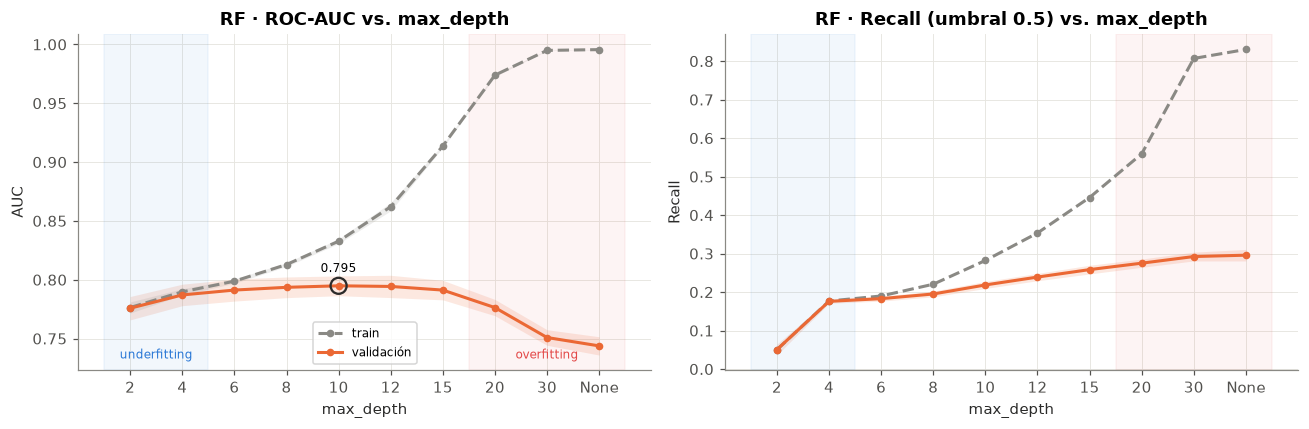

Mejor max_depth (AUC val): 10


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
2.0,0.776,0.010,0.776,0.005,0.051,0.014,0.050,0.779,3.988
4.0,0.787,0.009,0.790,0.003,0.176,0.005,0.177,0.720,6.376
6.0,0.791,0.009,0.799,0.002,0.183,0.006,0.190,0.715,7.783
8.0,0.794,0.009,0.813,0.002,0.195,0.007,0.220,0.699,9.318
10.0,0.795,0.008,0.833,0.002,0.219,0.009,0.282,0.669,8.970
12.0,0.794,0.009,0.862,0.003,0.239,0.010,0.353,0.637,10.366
15.0,0.791,0.008,0.914,0.001,0.258,0.011,0.446,0.611,9.596
20.0,0.776,0.007,0.974,0.001,0.275,0.011,0.559,0.571,9.674
30.0,0.751,0.007,0.995,0.000,0.292,0.011,0.807,0.471,9.821


In [3]:
PROF = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]
rf_prof = curva_validacion("rf_max_depth",
    lambda v: RandomForestClassifier(n_estimators=100, max_depth=v, random_state=RANDOM_STATE, n_jobs=1), PROF)
res_rf_prof = resumir(rf_prof)
MEJOR_PROF = mejor_valor(res_rf_prof)
MEJOR_PROF = None if pd.isna(MEJOR_PROF) else int(MEJOR_PROF)
etq = ["None" if pd.isna(v) else str(int(v)) for v in res_rf_prof.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
graficar_curva(axes[0], res_rf_prof, "auc", "RF · ROC-AUC vs. max_depth", "max_depth", etiquetas=etq)
graficar_curva(axes[1], res_rf_prof, "recall", "RF · Recall (umbral 0.5) vs. max_depth", "max_depth", etiquetas=etq, marcar=False)
axes[0].legend(fontsize=8)
for ax in axes:
    ax.axvspan(-0.5, 1.5, color="#2a78d6", alpha=0.06); ax.axvspan(len(etq) - 3.5, len(etq) - 0.5, color="#e34948", alpha=0.06)
axes[0].text(0.5, axes[0].get_ylim()[0] + 0.01, "underfitting", ha="center", fontsize=8, color="#2a78d6")
axes[0].text(len(etq) - 2, axes[0].get_ylim()[0] + 0.01, "overfitting", ha="center", fontsize=8, color="#e34948")
guardar("13_rf_max_depth")
print("Mejor max_depth (AUC val):", MEJOR_PROF)
res_rf_prof.round(3)

**Lectura de la curva (`max_depth`):**
- **Underfitting (izquierda):** con `max_depth = 2`, train y validación coinciden (AUC ≈ 0.776) pero son bajos, y el recall es casi nulo (0.05): los árboles son tan simples que casi nunca llegan a una hoja con mayoría de `yes`.
- **Zona óptima:** la validación sube hasta **0.795 con `max_depth = 10`** (8–12 quedan a ≤ 0.001). Gap train–validación de solo 0.04.
- **Overfitting (derecha):** desde 15 el AUC de train sigue subiendo hasta 0.996, mientras que el de validación **cae** hasta 0.744 (el valor por defecto, `None`). Los árboles profundos memorizan ruido del train (y la "huella de la fecha" que vimos en el Paso 2).
- El recall con umbral 0.5 baja al limitar la profundidad (0.30 → 0.22): árboles menos profundos dan probabilidades menos extremas y menos casos superan 0.5. No es un problema del modelo sino del umbral, que se ajusta en el Paso 4.

**Elegido: `max_depth = 10`.**

#### b) Número de árboles (`n_estimators`), con la mejor profundidad
Más árboles → predicción más estable (se promedian más votos), hasta que la mejora se satura; el costo crece linealmente.

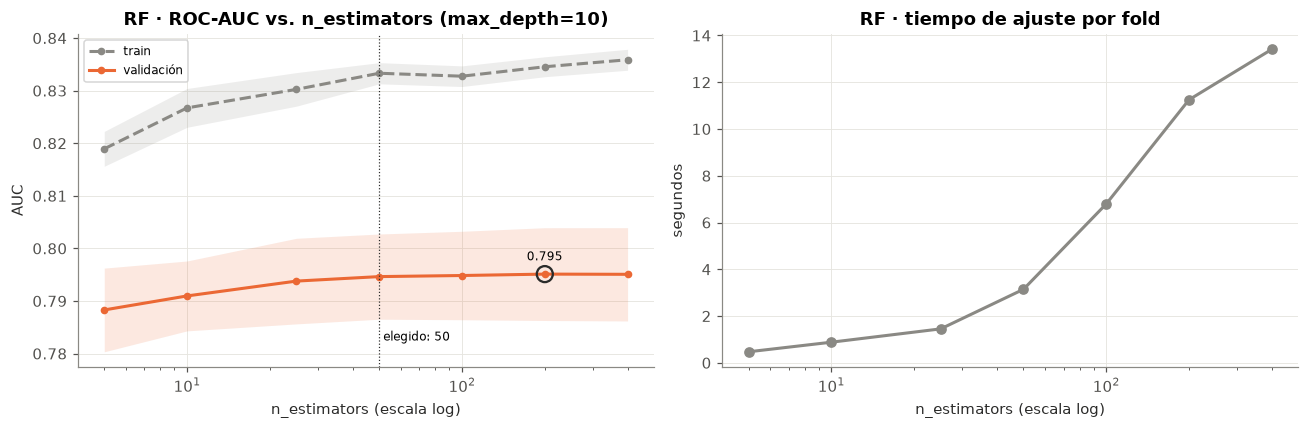

n_estimators elegido: 50


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
5,0.788,0.008,0.819,0.003,0.226,0.014,0.289,0.635,0.471
10,0.791,0.007,0.827,0.004,0.226,0.012,0.293,0.638,0.881
25,0.794,0.008,0.830,0.003,0.231,0.013,0.297,0.656,1.452
50,0.795,0.008,0.833,0.002,0.224,0.012,0.291,0.657,3.144
100,0.795,0.008,0.833,0.002,0.219,0.009,0.282,0.669,6.797
200,0.795,0.009,0.835,0.002,0.218,0.010,0.284,0.668,11.252
400,0.795,0.009,0.836,0.002,0.220,0.009,0.287,0.662,13.409


In [4]:
N_ARB = [5, 10, 25, 50, 100, 200, 400]
rf_narb = curva_validacion(f"rf_n_estimators_depth{MEJOR_PROF}",
    lambda v: RandomForestClassifier(n_estimators=v, max_depth=MEJOR_PROF, random_state=RANDOM_STATE, n_jobs=1), N_ARB)
res_rf_narb = resumir(rf_narb)

# Criterio: el menor número de árboles cuyo AUC está a menos de 0.001 del máximo (la curva ya se saturó)
MEJOR_NARB = int(menor_en_meseta(res_rf_narb))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
graficar_curva(axes[0], res_rf_narb, "auc", f"RF · ROC-AUC vs. n_estimators (max_depth={MEJOR_PROF})", "n_estimators (escala log)", log=True)
axes[0].axvline(MEJOR_NARB, color="#2b2b2a", lw=0.8, ls=":")
axes[0].text(MEJOR_NARB, axes[0].get_ylim()[0] + 0.005, f" elegido: {MEJOR_NARB}", fontsize=8)
axes[0].legend(fontsize=8)
axes[1].plot(res_rf_narb.index, res_rf_narb["t_fit_s"], "o-", color=C_GRIS, lw=2)
axes[1].set(xscale="log", title="RF · tiempo de ajuste por fold", xlabel="n_estimators (escala log)", ylabel="segundos")
guardar("14_rf_n_estimators")
print("n_estimators elegido:", MEJOR_NARB)
res_rf_narb.round(3)

**Lectura de la curva (`n_estimators`):** el AUC sube de 0.788 (5 árboles) a 0.795 (50) y desde ahí queda **plano** (0.7946–0.7951 hasta 400), mientras el tiempo de ajuste crece de forma lineal. A diferencia de la profundidad, agregar árboles **no produce overfitting**: la curva de train también se estabiliza, porque promediar más árboles solo reduce la varianza de la predicción (clase 7).

**Elegido: `n_estimators = 50`** (el menor valor en la meseta: mismo AUC, 4 veces más rápido que 200).

### 3.3 KNN — número de vecinos (`k`) y ponderación
- `k` impares (evita empates en clasificación binaria).
- Dos variantes: **uniforme** (cada vecino vota igual) y **ponderado por distancia** (cada vecino pesa 1/distancia, clase 9).
- Ojo con la curva de *train* del KNN ponderado: cada punto de train es su propio vecino a distancia 0, así que en train siempre "acierta" → su curva de train no es informativa (por eso se muestra solo la de uniforme).

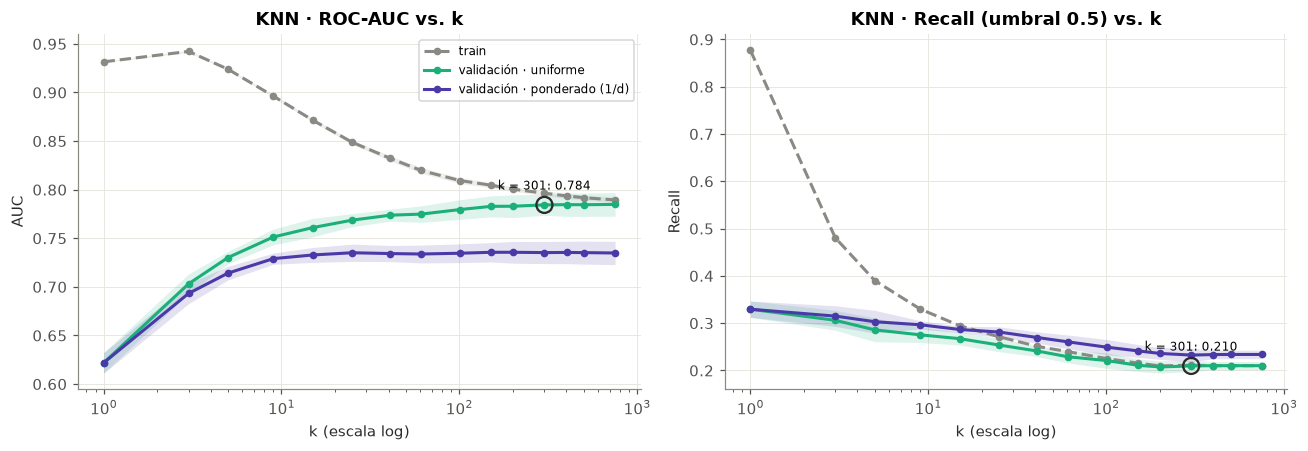

Mejor uniforme: k=301 (AUC 0.784) | mejor ponderado: k=25 (AUC 0.735)
Elegido (criterio de meseta): 301 uniform


uniforme                    ponderado           
      train_auc val_auc val_recall   val_auc val_recall
valor                                                  
1         0.932   0.622      0.330     0.622      0.330
3         0.942   0.703      0.306     0.693      0.315
5         0.924   0.730      0.286     0.714      0.303
9         0.896   0.751      0.275     0.729      0.297
15        0.871   0.761      0.267     0.733      0.287
25        0.849   0.769      0.254     0.735      0.281
41        0.832   0.774      0.241     0.734      0.270
61        0.820   0.775      0.229     0.734      0.261
101       0.809   0.780      0.221     0.735      0.249
151       0.805   0.783      0.211     0.736      0.241
201       0.801   0.783      0.207     0.736      0.236
301       0.796   0.784      0.210     0.735      0.233
401       0.794   0.785      0.210     0.735      0.234
501       0.792   0.785      0.210     0.735      0.234
751       0.789   0.785      0.210     0.735      0.234

In [5]:
KS = [1, 3, 5, 9, 15, 25, 41, 61, 101, 151, 201, 301, 401, 501, 751]
knn_uni = curva_validacion("knn_uniform", lambda v: KNeighborsClassifier(n_neighbors=v, weights="uniform"), KS)
knn_dist = curva_validacion("knn_distance", lambda v: KNeighborsClassifier(n_neighbors=v, weights="distance"), KS)
res_knn_uni, res_knn_dist = resumir(knn_uni), resumir(knn_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
k_sel = menor_en_meseta(res_knn_uni)
for ax, met in zip(axes, ["auc", "recall"]):
    graficar_curva(ax, res_knn_uni, met, f"KNN · {'ROC-AUC' if met == 'auc' else 'Recall (umbral 0.5)'} vs. k",
                   "k (escala log)", log=True, color="#1baf7a", nombre_val="validación · uniforme", marcar=False)
    graficar_curva(ax, res_knn_dist, met, ax.get_title(), "k (escala log)", log=True, color="#4a3aa7",
                   nombre_val="validación · ponderado (1/d)", con_train=False, marcar=False)
    v = res_knn_uni.loc[k_sel, f"val_{met}"]
    ax.scatter([k_sel], [v], s=110, facecolor="none", edgecolor="#2b2b2a", lw=1.5, zorder=4)
    ax.annotate(f"k = {k_sel}: {v:.3f}", (k_sel, v), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
axes[0].legend(fontsize=8)
guardar("15_knn_k")

# Mismo criterio de meseta: k más chico = más barato y menos sesgo hacia la clase mayoritaria
mejor_uni, mejor_dist = menor_en_meseta(res_knn_uni), menor_en_meseta(res_knn_dist)
if res_knn_dist.loc[mejor_dist, "val_auc"] > res_knn_uni.loc[mejor_uni, "val_auc"]:
    MEJOR_K, MEJOR_PESO = int(mejor_dist), "distance"
else:
    MEJOR_K, MEJOR_PESO = int(mejor_uni), "uniform"
print(f"Mejor uniforme: k={mejor_uni} (AUC {res_knn_uni.loc[mejor_uni, 'val_auc']:.3f}) | "
      f"mejor ponderado: k={mejor_dist} (AUC {res_knn_dist.loc[mejor_dist, 'val_auc']:.3f})")
print("Elegido (criterio de meseta):", MEJOR_K, MEJOR_PESO)
pd.concat({"uniforme": res_knn_uni[["train_auc", "val_auc", "val_recall"]],
           "ponderado": res_knn_dist[["val_auc", "val_recall"]]}, axis=1).round(3)

**Lectura de la curva (`k`, pesos uniformes):**
- **Overfitting con `k` chico:** con `k = 1` el AUC de validación es 0.622 frente a 0.93 en train. Cada cliente se clasifica por un único vecino, y como las clases están muy mezcladas ese vecino suele ser "ruido". (El AUC de train no llega a 1 porque hay clientes idénticos en las 14 variables con etiquetas distintas.)
- Al aumentar `k`, el AUC de train baja y el de validación sube: el gap se cierra (0.19 con `k = 5`, **0.012 con `k = 301`**).
- **Meseta desde `k = 301`:** 401, 501 y 751 quedan a ≤ 0.001 (0.785). No se llega a una zona clara de underfitting en el rango probado.
- **¿Por qué un `k` tan grande?** La proporción de `yes` es baja en casi todas las regiones del espacio (~11 %) y las clases se superponen mucho: para estimar bien esa probabilidad local hacen falta muchos vecinos. Además, con `k = 301` la probabilidad puede tomar 302 valores distintos (con `k = 5` solo 6), lo que da un ranking mucho más fino → mejor AUC.
- **El recall baja con `k`** (0.33 → 0.21): un `k` grande favorece a la clase mayoritaria (clase 9). Se compensa eligiendo el umbral en el Paso 4.
- **Ponderación por distancia (1/d): peor** (meseta en ~0.735). Muchos clientes son idénticos o casi idénticos en el espacio de variables (distancia ≈ 0 → peso enorme), así que unos pocos vecinos dominan el voto y el modelo se comporta como un KNN de `k` chico.

**Elegido: `k = 301`, pesos uniformes.**

### 3.4 SVM
#### a) Parámetro de regularización `C` (kernel RBF)
`C` es el costo de violar el margen (clase 8): **C chico** → margen ancho, más regularización (riesgo de underfitting); **C grande** → prioriza clasificar bien el train (riesgo de overfitting). Se usa el **100 % de train** en cada fold (~26 000 filas), por lo que es el cálculo más largo del notebook (el tiempo de ajuste crece mucho con `C`).

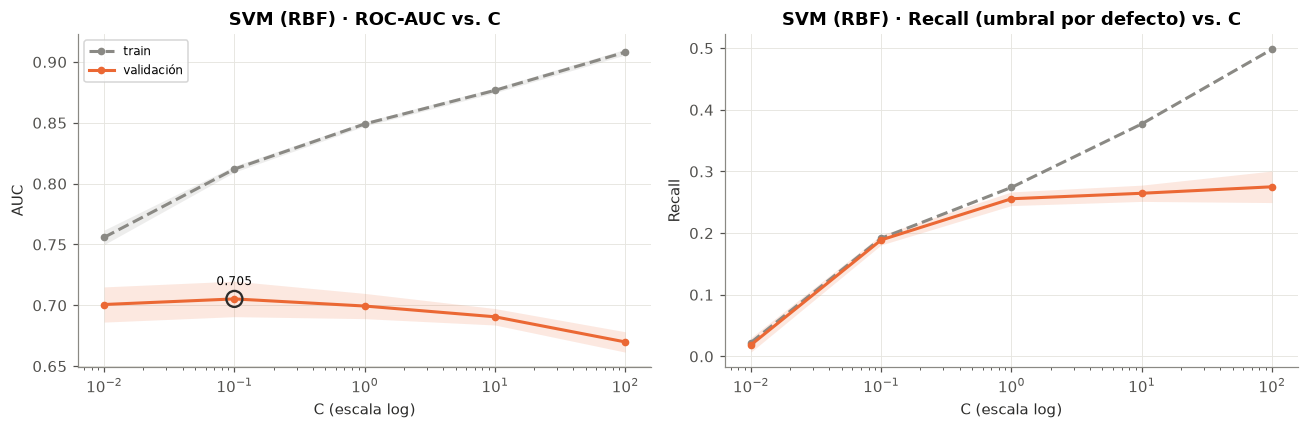

Mejor C: 0.1


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
0.01,0.701,0.014,0.756,0.006,0.019,0.012,0.022,0.778,111.299
0.10,0.705,0.015,0.812,0.003,0.189,0.008,0.192,0.696,191.781
1.00,0.699,0.010,0.849,0.002,0.256,0.011,0.274,0.654,402.720
10.00,0.691,0.007,0.877,0.002,0.265,0.013,0.377,0.595,625.080
100.00,0.670,0.008,0.908,0.002,0.275,0.026,0.498,0.507,680.023


In [6]:
CS = [0.01, 0.1, 1, 10, 100]
svm_c = curva_validacion("svm_C_rbf", lambda v: SVC(C=v, kernel="rbf", random_state=RANDOM_STATE), CS)
res_svm_c = resumir(svm_c)
MEJOR_C = float(mejor_valor(res_svm_c))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
graficar_curva(axes[0], res_svm_c, "auc", "SVM (RBF) · ROC-AUC vs. C", "C (escala log)", log=True)
graficar_curva(axes[1], res_svm_c, "recall", "SVM (RBF) · Recall (umbral por defecto) vs. C", "C (escala log)", log=True, marcar=False)
axes[0].legend(fontsize=8)
guardar("16_svm_C")
print("Mejor C:", MEJOR_C)
res_svm_c.round(3)

**Lectura de la curva (`C`, kernel RBF):** la curva de validación es bastante **plana** (0.670–0.705) y la diferencia la hace el gap:
- **Underfitting con `C = 0.01`:** margen tan ancho (mucha regularización) que el modelo casi no predice `yes` (recall 0.02).
- **Overfitting con `C` grande:** desde `C = 1` el AUC de train sube (0.849 → 0.908 con `C = 100`) mientras que el de validación cae (0.699 → 0.670). Con `C` grande el SVM prioriza clasificar bien cada punto de train en vez de mantener un margen amplio.
- **Costo:** el tiempo de ajuste por fold pasa de ~2 min (`C = 0.01`) a ~11 min (`C = 100`, con los ajustes en paralelo).

**Elegido: `C = 0.1`** (AUC 0.705).

#### b) Kernel (con el mejor `C`)
- **Lineal:** frontera = hiperplano en el espacio original.
- **Polinómico** (grado 3 por defecto): frontera curva, espacio ampliado con productos de variables.
- **RBF:** frontera local y flexible (cada vector de soporte influye en su vecindad, controlado por `gamma`).

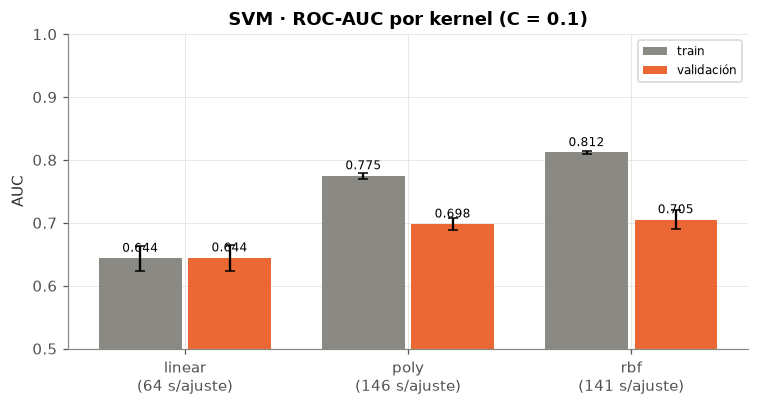

Mejor kernel: rbf


,val_auc,val_auc_std,train_auc,train_auc_std,val_recall,val_recall_std,train_recall,val_precision,t_fit_s
valor,,,,,,,,,
linear,0.644,0.021,0.644,0.020,0.206,0.004,0.207,0.645,63.878
poly,0.698,0.009,0.775,0.005,0.196,0.010,0.206,0.691,145.863
rbf,0.705,0.015,0.812,0.003,0.189,0.008,0.192,0.696,141.421


In [7]:
KERNELS = ["linear", "poly", "rbf"]
svm_k = curva_validacion(f"svm_kernel_C{MEJOR_C:g}",
                         lambda v: SVC(C=MEJOR_C, kernel=v, random_state=RANDOM_STATE), KERNELS)
res_svm_k = resumir(svm_k)
MEJOR_KERNEL = mejor_valor(res_svm_k)

fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(KERNELS))
for j, (parte, col) in enumerate([("train", C_GRIS), ("val", "#eb6834")]):
    v = res_svm_k.loc[KERNELS, f"{parte}_auc"].values
    e = res_svm_k.loc[KERNELS, f"{parte}_auc_std"].values
    ax.bar(x - 0.2 + 0.4 * j, v, width=0.37, yerr=e, capsize=3, color=col, label="train" if parte == "train" else "validación")
    for xp, val in zip(x - 0.2 + 0.4 * j, v):
        ax.text(xp, val + 0.01, f"{val:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, [f"{k}\n({res_svm_k.loc[k, 't_fit_s']:.0f} s/ajuste)" for k in KERNELS])
ax.set(title=f"SVM · ROC-AUC por kernel (C = {MEJOR_C:g})", ylim=(0.5, 1.0), ylabel="AUC")
ax.legend(fontsize=8)
guardar("17_svm_kernel")
print("Mejor kernel:", MEJOR_KERNEL)
res_svm_k.round(3)

**Lectura (kernel, `C = 0.1`):**
- **Lineal: underfitting claro.** AUC 0.644 tanto en train como en validación: un hiperplano en el espacio original no alcanza para separar las clases. Es coherente con el EDA (relación en "U" con la edad, efectos fuertes de `month` y `poutcome` que no son lineales).
- **Polinómico (0.698) y RBF (0.705):** fronteras no lineales; RBF es levemente mejor.

**Elegido: kernel RBF.** Aun ajustado, SVM es el modelo más débil. Posibles causas: las clases están muy superpuestas, la mayoría de las 49 columnas son binarias (one-hot) y la distancia al hiperplano no está pensada para ordenar clientes por probabilidad. Una mejora pendiente sería ajustar `C` y `gamma` en conjunto (clase 8), pero cada combinación cuesta varios minutos con el train completo.

### 3.5 Comparación: hiperparámetros por defecto vs. ajustados
Los modelos ajustados se evalúan con los **mismos 5 folds** del Paso 2 (el set y los folds son idénticos, así que los números son directamente comparables). Se guardan también las **predicciones fuera de fold** de cada modelo ajustado: en el Paso 4 se usarán para **elegir el umbral solo con train**.

In [8]:
MODELOS_AJUSTADOS = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(C=MEJOR_C, kernel=MEJOR_KERNEL, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=MEJOR_K, weights=MEJOR_PESO),
    "Random Forest": RandomForestClassifier(n_estimators=MEJOR_NARB, max_depth=MEJOR_PROF,
                                            random_state=RANDOM_STATE, n_jobs=1),
}
for m, est in MODELOS_AJUSTADOS.items():
    print(f"{m:14s} → {est}")

def _oof(nombre, k, idx_tr, idx_va):
    from sklearn.base import clone
    pipe = Pipeline([("pre", crear_preprocesador(SET)), ("modelo", clone(MODELOS_AJUSTADOS[nombre]))])
    pipe.fit(Xtr.iloc[idx_tr], y_train.iloc[idx_tr])
    X_v, X_a = Xtr.iloc[idx_va], Xtr.iloc[idx_tr]
    return (nombre, k, idx_va, score_continuo(pipe, X_v), pipe.predict(X_v),
            roc_auc_score(y_train.iloc[idx_tr], score_continuo(pipe, X_a)),
            recall_score(y_train.iloc[idx_tr], pipe.predict(X_a)))

CACHE_AJ = RESULTADOS / "paso3_modelos_ajustados.joblib"
if CACHE_AJ.exists() and not RECALCULAR:
    res_aj, oof_aj = joblib.load(CACHE_AJ)
else:
    t0 = time.time()
    orden = sorted(MODELOS_AJUSTADOS, key=lambda m: m != "SVM")
    salida = Parallel(n_jobs=-1)(delayed(_oof)(m, k, tr, va) for m in orden for k, (tr, va) in enumerate(FOLDS))
    print(f"{len(salida)} entrenamientos en {(time.time() - t0)/60:.1f} min")
    filas, oof_aj = [], {}
    for m, k, idx, sc, pr, tr_auc, tr_rec in salida:
        y_v = y_train.iloc[idx]
        filas.append({"modelo": m, "fold": k, "val_auc": roc_auc_score(y_v, sc), "val_recall": recall_score(y_v, pr),
                      "val_precision": precision_score(y_v, pr, zero_division=0), "train_auc": tr_auc, "train_recall": tr_rec})
        d = oof_aj.setdefault(m, {"score": np.zeros(len(Xtr)), "pred": np.zeros(len(Xtr), int)})
        d["score"][idx], d["pred"][idx] = sc, pr
    res_aj = pd.DataFrame(filas)
    joblib.dump((res_aj, oof_aj), CACHE_AJ)

# Resultados por defecto (Paso 2, mismo set y mismos folds)
res_def, _ = joblib.load(RESULTADOS / "paso2_cv.joblib")
res_def = res_def[res_def.set == SET]

ORDEN = list(MODELOS_AJUSTADOS)
comp = pd.concat({
    "por defecto": res_def.groupby("modelo")[["val_auc", "val_recall", "val_precision", "train_auc"]].mean(),
    "ajustado": res_aj.groupby("modelo")[["val_auc", "val_recall", "val_precision", "train_auc"]].mean(),
}, axis=1).reindex(ORDEN)
comp[("Δ", "AUC val")] = comp[("ajustado", "val_auc")] - comp[("por defecto", "val_auc")]
comp[("Δ", "gap AUC (train − val)")] = ((comp[("ajustado", "train_auc")] - comp[("ajustado", "val_auc")])
                                        - (comp[("por defecto", "train_auc")] - comp[("por defecto", "val_auc")]))
comp.round(3)

Naive Bayes    → GaussianNB()
SVM            → SVC(C=0.1, random_state=42)
KNN            → KNeighborsClassifier(n_neighbors=301)
Random Forest  → RandomForestClassifier(max_depth=10, n_estimators=50, n_jobs=1, random_state=42)


por defecto                                    ajustado  \
                  val_auc val_recall val_precision train_auc  val_auc   
modelo                                                                  
Naive Bayes         0.759      0.539         0.315     0.761    0.759   
SVM                 0.699      0.256         0.654     0.849    0.705   
KNN                 0.730      0.286         0.522     0.924    0.784   
Random Forest       0.744      0.296         0.456     0.996    0.795   

                                                       Δ                        
              val_recall val_precision train_auc AUC val gap AUC (train − val)  
modelo                                                                          
Naive Bayes        0.539         0.315     0.761   0.000                 0.000  
SVM                0.189         0.696     0.812   0.006                -0.043  
KNN                0.210         0.654     0.796   0.054                -0.182  
Random Forest      0.224         0.657     0.833   0.051                -0.213

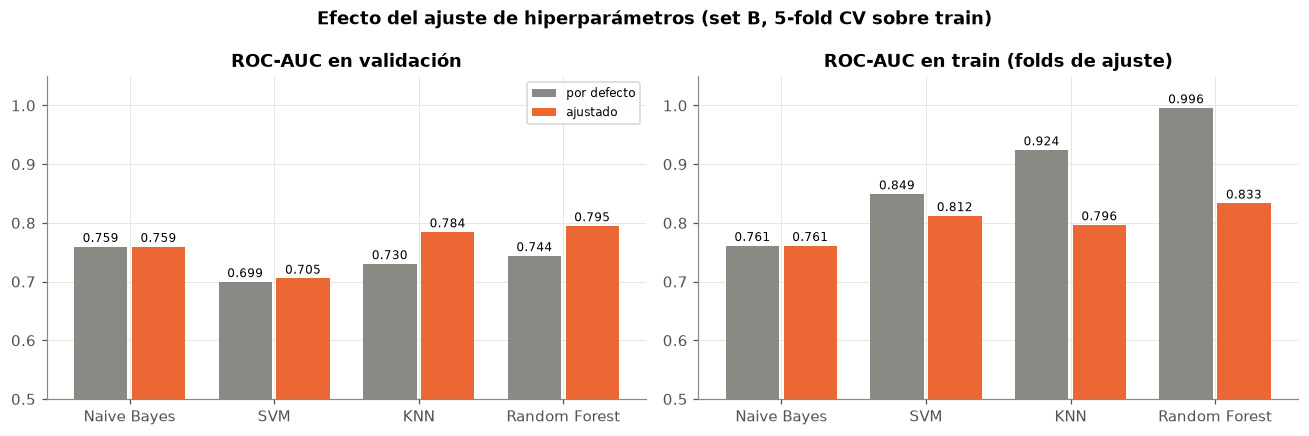

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(ORDEN))
for ax, met, tit in zip(axes, ["val_auc", "train_auc"], ["ROC-AUC en validación", "ROC-AUC en train (folds de ajuste)"]):
    for j, (cual, col) in enumerate([("por defecto", C_GRIS), ("ajustado", "#eb6834")]):
        v = comp[(cual, met)].values
        ax.bar(x - 0.2 + 0.4 * j, v, width=0.37, color=col, label=cual)
        for xp, val in zip(x - 0.2 + 0.4 * j, v):
            ax.text(xp, val + 0.008, f"{val:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x, ORDEN); ax.set(title=tit, ylim=(0.5, 1.05))
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Efecto del ajuste de hiperparámetros (set B, 5-fold CV sobre train)", fontweight="bold")
guardar("18_defecto_vs_ajustado")

**Lectura:**
- **Random Forest:** 0.744 → **0.795** de AUC (+0.051), y el gap train–validación pasa de 0.25 a 0.04.
- **KNN:** 0.730 → **0.784** (+0.054), gap de 0.19 a 0.01.
- **SVM:** apenas +0.006. Su curva era plana y el valor por defecto (`C = 1`) ya estaba cerca del óptimo.
- **Naive Bayes:** sin cambios (no se ajustó). Pasa del 1.er al 3.er lugar.
- La mejora viene casi toda de **reducir el overfitting**: los modelos ajustados son más simples (árboles menos profundos, más vecinos) y generalizan mejor.
- El recall con umbral 0.5 **baja** en los modelos ajustados (0.19–0.22): sus probabilidades son menos extremas, así que pocos clientes superan 0.5. El recall final dependerá del umbral que se elija en el Paso 4 con las predicciones fuera de fold que se guardaron acá.

### 3.6 Conclusiones del Paso 3

1. **Las curvas de validación muestran los patrones esperados.** En RF (`max_depth`) y SVM (`C`): underfitting en el extremo simple y overfitting en el extremo complejo, con un óptimo intermedio. En KNN: overfitting con `k` chico, que se corrige aumentando `k`. En RF, `n_estimators` solo estabiliza (no produce overfitting).
2. **Hiperparámetros elegidos** (criterio: máximo AUC de validación, o el menor valor de la meseta cuando "más" solo agrega costo):

| Modelo | Hiperparámetros | AUC val (defecto → ajustado) |
|---|---|---|
| Random Forest | `max_depth = 10`, `n_estimators = 50` | 0.744 → **0.795** |
| KNN | `k = 301`, pesos uniformes | 0.730 → **0.784** |
| Naive Bayes | (sin ajuste) | 0.759 |
| SVM | kernel RBF, `C = 0.1` | 0.699 → 0.705 |

3. **Candidato a modelo final: Random Forest.** Tiene el mejor AUC, un gap chico (0.04), es rápido para predecir y permite ver la importancia de las variables. KNN queda cerca (0.784), pero para cada predicción tiene que calcular la distancia a los 33 000 clientes de train y es menos interpretable.
4. **Para el Paso 4:** entrenar el modelo elegido con todo el train, **elegir el umbral con las predicciones fuera de fold** (solo train, criterio del punto de la ROC más cercano a (0, 1), clase 4) y recién ahí evaluar **una única vez en test**.